# CIS I — Assignment 1: Pivot Calibration

This notebook walks through the pivot-calibration scenario from the
assignment (Figure 1): a pointer and a calibration object, each
carrying a marker body, observed by an optical tracker. Your job is to
**design** the marker-sphere layouts and workspace placements, then
**calibrate** the pointer's tip position `p_tip` to within about 2mm.

Everything runs against `src.simulation`, a self-contained simulator that plays the role of the physical tracker +
hand-guided robot + calibration sensor described in the handout. It injects measurement noise — your code never sees ground truth
except where explicitly noted for **validation/reporting** in Step 8 (real
hardware wouldn't give you that; the point there is to report your achieved
accuracy, not to use the ground truth in your calibration math itself).



In [169]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..")))

import numpy as np
from src import simulation
from src import vct3, Rot, Frame

np.set_printoptions(precision=3, suppress=True)


## Step 1: Design the pointer's marker body

Choose approximate local marker-sphere positions `a_ptr,k` (a `List[vct3]`,
relative to the pointer's own coordinate frame) and the pointer tip's
approximate local position `p_tip_approx`. These are your
*nominal design values* — the simulator will independently perturb the
*actual* manufactured positions by a small, noise amount (bounded at
2mm).


In [ ]:
ptr_local_positions = [
    vct3(0,0,0),
    vct3(50,0,0),
    vct3(0,80,0),
    vct3(0,0,60)

]
ptr_tip_approx = vct3(0,0,-250)  # TODO: vct3, the tip's approximate position in the pointer's local frame


## Step 1.1: Design the calibration object's marker body

Same idea, for the calibration object's local marker positions `a_cal,k`.


In [171]:
cal_local_positions = [
    vct3(400,-200,0),
    vct3(400,200,0),
    vct3(-400,-200,0),
    vct3(-400,200,0)
]


## Step 2: Approximate workspace poses

Specify approximate poses (as `Frame` class from src) for the tracking camera
(`F_tracker`) and the calibration object (`F_cal`), relative to the
workspace. The tracker's usable volume is the tetrahedral region in the
handout's Figure 2 (roughly 100-200cm in front of the tracker, widening
from ~120cm to ~200cm across) — place the calibration object, and later
the pointer, so they're inside that volume.


In [172]:
F_tracker_approx = Frame.eye() # TODO: Frame, tracker pose relative to the workspace
F_cal_approx = Frame(Rot.eye(), vct3(1650,0,0))      # TODO: Frame, calibration object pose relative to the workspace


## *Step 2.1: Visualization

Nominal geometric FOV checks (mm; negative margin = outside):
  calibrator_markers_inside: True
  calibrator_marker_min_margin_mm: 150.0
  calibration_pointer_markers_inside: True
  calibration_pointer_min_margin_mm: 457.67949192431115
  test_body_origins_inside: False
  test_body_origin_min_margin_mm: -900.0
  pointer_marker_max_radius_from_body_origin_mm: 40.0
  test_markers_guaranteed_inside_any_orientation: False
  test_marker_conservative_min_margin_mm: -940.0
Note: approximate frustum only; no occlusion or simulation clipping check.


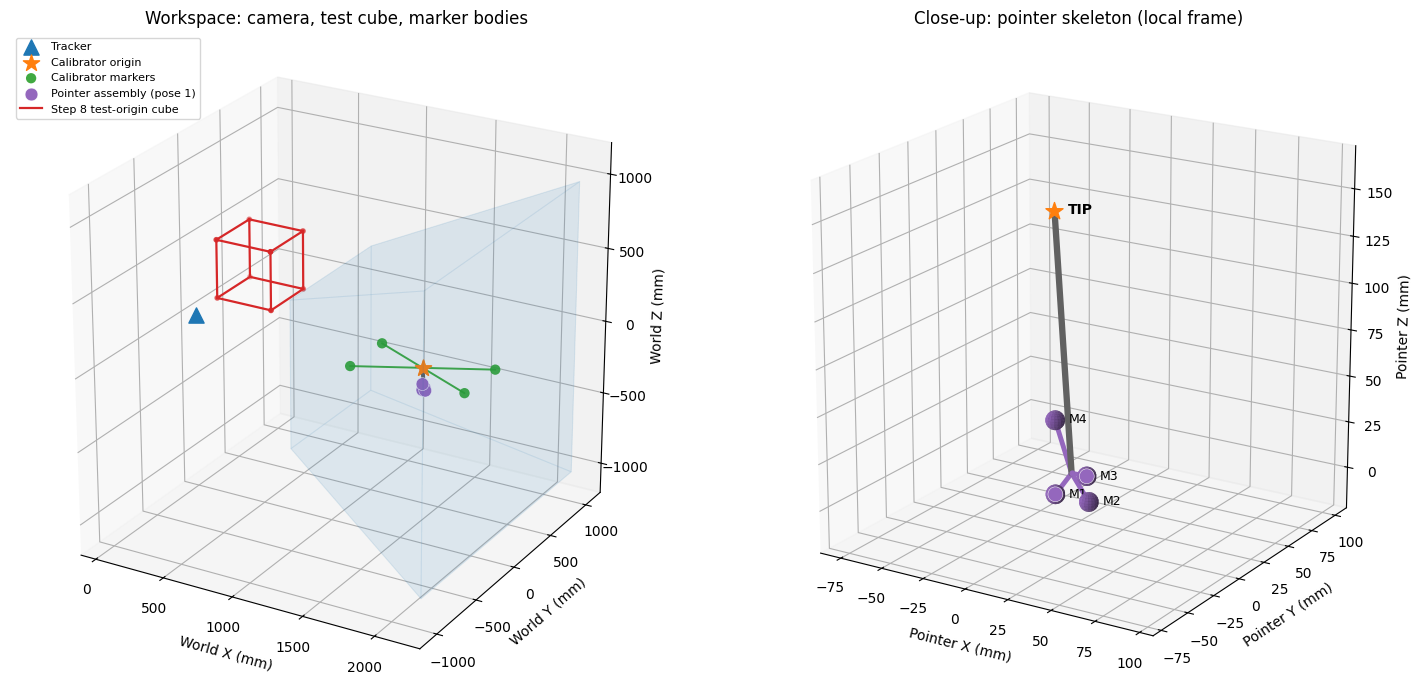

In [173]:
from functions.workspace_viz import plot_workspace

fig, ax, report = plot_workspace(
    F_tracker_approx,
    F_cal_approx,
    ptr_local_positions,
    ptr_tip_approx,
    cal_local_positions
)

## Step 3: Build the simulation

Fully provided — this just wires up your Step 1/2 design choices through
`simulation`'s `DefineMarkerBody` / `PlaceMarkerBody` / `CreateTracker`
equivalents. `ptr_placed`/`cal_placed` are `PlacedBody` handles: each pairs
a `MarkerBody` with its hidden actual placement, and gets passed to
`simulation.sample_marker_bodies(...)` whenever you want a reading.


In [174]:
#manufaturing error
ptr_mb = simulation.define_marker_body("ptr_mb", ptr_local_positions)
cal_mb = simulation.define_marker_body("cal_mb", cal_local_positions)

#placement error
cal_placed = simulation.place_marker_body(cal_mb, F_cal_approx)
# The pointer's own body doesn't have a meaningful "workspace placement" yet
# It moves every time it's hand-guided (Step 4-6). 
# precision="precise" matches a robot-controlled pose rather than a coarsely, manually placed
# static object (see place_marker_body's docstring).
ptr_placed = simulation.place_marker_body(ptr_mb, Frame.eye(), precision="precise")

ptr = simulation.define_pointer("ptr1", ptr_tip_approx, ptr_mb)
trk = simulation.create_tracker("trk1", F_tracker_approx)

print("simulation built:", ptr_mb.name, cal_mb.name, ptr.name, trk.name)


simulation built: ptr_mb cal_mb ptr1 trk1


## Step 3.1: Refine `a_ptr,k` / `a_cal,k`

> "Observations of marker positions can be used to determine accurate
> estimates of relative positions a_ptr,k of markers on pointer and
> calibration objects... **Hint**: You probably want to take multiple
> readings in order to reduce the uncertainty associated with the a_k
> values."


In [175]:
def refine_marker_body(trk, placed, n_readings=30, passes=3):
    """
    TODO: implement

    input:
        trk - Tracker to read with
        placed - PlacedBody whose body's nominal marker positions should be
            refined in place (via body.set_marker_positions(...))
        n_readings - int, readings to average per pass
        passes - int, how many times to repeat
    output: None (mutates placed.body's nominal_marker_positions in place)
    """
#calibration body samples
    for i in range(passes):

        reading_a_values = []

        for j in range(n_readings):
            readings = simulation.sample_marker_bodies(
                    trk,
                    [placed]
                )
            F_inv = readings[placed.body.name].frame.inv()
            obs_b = readings[placed.body.name].markers
            new_a_positions = []

            for marker in obs_b:
                b = marker.p
                a = F_inv * b

                new_a_positions.append([a.x, a.y, a.z])

            reading_a_values.append(new_a_positions)

        # Stack all 30 readings
        stacked = np.stack(reading_a_values)

        # Calculating mean column by column
        mean_a = np.mean(stacked, axis=0)

        # Convert back to vct3 objects
        mean_positions = [
                    vct3(*row)
                    for row in mean_a
                ]

                # Update marker body positions
        placed.body.set_marker_positions(mean_positions)
refine_marker_body(trk, ptr_placed)
refine_marker_body(trk, cal_placed)

## Steps 4-6: Collect pivot-calibration observations

For each observation `j`: hand-guide the pointer near the calibration
object at some desired orientation `R_desired,j`, take one simultaneous
tracker reading of *both* bodies, and read the calibration sensor. Loop
skeleton is provided; you choose how many observations to take and how to
vary `R_desired,j`


In [176]:
N_OBSERVATIONS = 30  # TODO

def rotation_distance_deg(R1, R2):

    # Calculate relative rotation matrix
    R_relative = R1.matrix.T @ R2.matrix

    # Calculate relative rotation angle
    cos_theta = (np.trace(R_relative) - 1) / 2

    # Avoid numerical errors
    cos_theta = np.clip(cos_theta, -1.0, 1.0)

    theta = np.arccos(cos_theta)

    return np.degrees(theta)

min_angle_diff = 25.0
rng = np.random.default_rng(42)

accepted_rotations = []
accepted_angles = []

F_ptr_list = []
F_cal_list = []
sensed_tip_list = []
for j in range(N_OBSERVATIONS):

    while True:

        # 1. Generate random XYZ Euler angles
        rx = int(rng.integers(-70, 71))
        ry = int(rng.integers(-70, 71))
        rz = int(rng.integers(-70, 71))

        R_desired = Rot.xyz_deg(rx, ry, rz)  # TODO: vary the desired pointer orientation across observations

        too_close = False

        for R_old in accepted_rotations:
            distance = rotation_distance_deg(R_desired, R_old)

            if distance < min_angle_diff:
                too_close = True
                break

        if too_close:
            continue

        hg = simulation.hand_guide_pointer(ptr, ptr_placed, cal_placed, R_desired)
        obs = simulation.sample_marker_bodies(trk, [ptr_placed, cal_placed])
        sensed = simulation.sense_tip(ptr, hg)

        if sensed is None:
            continue

        F_ptr_list.append(obs["ptr_mb"].frame)
        F_cal_list.append(obs["cal_mb"].frame)
        sensed_tip_list.append(sensed)

        accepted_rotations.append(R_desired)
        accepted_angles.append((rx, ry, rz))

        break


print(f"collected {len(F_ptr_list)} observations")


collected 30 observations


`sensed_tip_list` holds each observation's high-accuracy calibration-sensor
reading (or `None` if that observation ended up outside the sensor's 5mm
range) — useful as an independent sanity check on your calibration later,
since it measures the tip position a completely different way (directly,
rather than through the pointer's marker geometry).


## Step 7: Compute a calibrated value for `p_tip`

This is the assignment's core deliverable — implement it yourself and specify the details of implementation in the report.

**Corner case to consider**: What are the corner cases you want to analyse here?

**Minimum data**: how many observations, and what about their rotations,
are needed for the stacked system to actually be solvable? How do you define whether a system is solvable here? Include that in your report


In [177]:
def compute_pivot_calibration(F_ptr_list, F_cal_list):
    """
    TODO: implement.

    input:
        F_ptr_list - List[Frame], the pointer marker body's pose relative to
            the tracker for each observation j (Fptr,j)
        F_cal_list - List[Frame], the calibration object's pose relative to
            the tracker for each observation j (Fcal,j), same order/length
    output:
        p_tip - vct3, the calibrated tip position in the pointer's local frame
        cov_estimate - np.ndarray (3x3), an estimated covariance for p_tip
            (e.g. from the least-squares fit's residuals)
    """

    

    if len(F_ptr_list) != len(F_cal_list):
        raise ValueError("The two lists must have the same length")

    # 1. Construct A and b
    A = []
    b = []

    for j in range(len(F_ptr_list)):

        F_ptr = F_ptr_list[j]
        F_cal = F_cal_list[j]

        R_ptr = F_ptr.R.matrix
        R_cal = F_cal.R.matrix

        # A_j = [R_ptr, -R_cal], three rows
        for i in range(3):

            row = []

            for k in range(3):
                row.append(R_ptr[i, k])

            for k in range(3):
                row.append(-R_cal[i, k])

            A.append(row)

        # b_j = t_cal - t_ptr
        b.append(F_cal.p.x - F_ptr.p.x)
        b.append(F_cal.p.y - F_ptr.p.y)
        b.append(F_cal.p.z - F_ptr.p.z)

    # 2. Construct normal equations:
    # (A^T A) x = A^T b

    M = [[0.0] * 7 for _ in range(6)]

    for i in range(len(A)):

        for c in range(6):

            # Right-hand side: A^T b
            M[c][6] += A[i][c] * b[i]

            # Left-hand side: A^T A
            for d in range(6):
                M[c][d] += A[i][c] * A[i][d]

    # 3. Gaussian elimination with partial pivoting

    for col in range(6):

        pivot = max(
            range(col, 6),
            key=lambda r: abs(M[r][col])
        )

        if abs(M[pivot][col]) < 1e-10:
            raise ValueError("Calibration system may be rank deficient")

        M[col], M[pivot] = M[pivot], M[col]

        for r in range(col + 1, 6):

            factor = M[r][col] / M[col][col]

            for c in range(col, 7):
                M[r][c] -= factor * M[col][c]

    # 4. Back substitution

    x = [0.0] * 6

    for i in range(5, -1, -1):

        value = M[i][6]

        for k in range(i + 1, 6):
            value -= M[i][k] * x[k]

        x[i] = value / M[i][i]

    # 5. Extract calibrated tip position

    p_tip = vct3(x[0], x[1], x[2])

    print("Estimated pivot point:", x[3:6])

    # 6. Calculate residual variance
    residual_sum = 0.0

    for i in range(len(b)):

        predicted_b = 0.0

        for k in range(6):
            predicted_b += A[i][k] * x[k]

        error = predicted_b - b[i]

        residual_sum += error ** 2

    sigma_squared = residual_sum / (len(b) - 6)

    # 7. Calculate A^T A
    ATA = [[0.0] * 6 for _ in range(6)]

    for row in A:
        for i in range(6):
            for j in range(6):
                ATA[i][j] += row[i] * row[j]

    # 8. Calculate inverse of A^T A using Gauss-Jordan elimination
    augmented = []

    for i in range(6):

        row = ATA[i].copy()

        for j in range(6):
            if i == j:
                row.append(1.0)
            else:
                row.append(0.0)

        augmented.append(row)

    for col in range(6):

        # Find pivot row
        pivot = max(
            range(col, 6),
            key=lambda r: abs(augmented[r][col])
        )

        if abs(augmented[pivot][col]) < 1e-10:
            raise ValueError("Cannot calculate covariance: singular matrix")

        augmented[col], augmented[pivot] = augmented[pivot], augmented[col]

        # Normalize pivot row
        pivot_value = augmented[col][col]

        for j in range(12):
            augmented[col][j] /= pivot_value

        # Eliminate other rows
        for i in range(6):

            if i != col:

                factor = augmented[i][col]

                for j in range(12):
                    augmented[i][j] -= factor * augmented[col][j]

    # 9. Extract inverse matrix
    ATA_inv = []

    for i in range(6):
        ATA_inv.append(augmented[i][6:12])

    # 10. Calculate covariance of p_tip (top-left 3x3)
    cov_tip = []

    for i in range(3):

        row = []

        for j in range(3):
            row.append(sigma_squared * ATA_inv[i][j])

        cov_tip.append(row)

    return p_tip, np.array(cov_tip)



    print("Calibrated tip:", p_tip_est)



p_tip_est, p_tip_cov = compute_pivot_calibration(F_ptr_list, F_cal_list)


Estimated pivot point: [np.float64(0.016023087589113905), np.float64(-0.29977692918519194), np.float64(0.24349745820810018)]


In [178]:
print("calibrated p_tip:", p_tip_est)
print("estimated covariance (mm^2):\n", p_tip_cov)



calibrated p_tip: vct3(x=1.21, y=-3.28, z=150.75)
Internal Vector:
[[  1.211]
 [ -3.276]
 [150.747]]
estimated covariance (mm^2):
 [[ 0.137  0.001 -0.009]
 [ 0.001  0.13  -0.001]
 [-0.009 -0.001  0.158]]


## Step 8: Validate against test poses

> "**Hint**: You may want to consider placing additional marker bodies
> close to (but not inside) the cube defined by the test volume. However,
> this will also depend on your design for and placement of the
> calibration object."

The nominal test-pose grid is `theta_x, theta_y, theta_z` each in
`{0, +-pi/6, +-pi/3, +-pi/2}` and `p_x, p_y, p_z` each in
`{300, 300+-100, 300+-200}` mm. For each test pose, the assignment requires a
**single observation only** (no averaging).

Think about why the hint suggests an *additional*, nearby reference body?

In [179]:
p_tip_true = ptr.get_actual_tip_position().p

tip_error = (p_tip_est - p_tip_true).norm()

print("Estimated tip:", p_tip_est)
print("True tip:", p_tip_true)
print(f"Tip calibration error: {tip_error:.4f} mm")

Estimated tip: vct3(x=1.21, y=-3.28, z=150.75)
Internal Vector:
[[  1.211]
 [ -3.276]
 [150.747]]
True tip: vct3(x=0.51, y=0.93, z=151.80)
Internal Vector:
[[  0.513]
 [  0.932]
 [151.802]]
Tip calibration error: 4.3938 mm


In [180]:
near_local_positions = [
    vct3(0, 0, 0),
    vct3(30, 0, 0),
    vct3(0, 40, 0),
    vct3(0, 0, 50)
    # TODO: at least 4 non-coplanar vct3 points for this reference body
]
F_near_approx = Frame(
    Rot.eye(),
    vct3(600, 300, 300)
)  # TODO: Frame, placed close to (not inside) the test-pose cube

near_mb = simulation.define_marker_body("near_mb", near_local_positions)
near_placed = simulation.place_marker_body(near_mb, F_near_approx)
refine_marker_body(trk, near_placed)


Refine this new body's geometry the same way you refined the pointer's and
calibration object's (Step 3b) before using it.


Now the single-observation test loop. For each nominal test pose `F_t`:
place the pointer there (small, robot-precision placement error, same as
the real system), take one simultaneous reading of the pointer and your
Step-8 reference body, and predict the tip's position (relative to that
reference body) using your calibrated `p_tip`.

**Ground truth for reporting only**: `PlacedBody.actual_placement` and
`MarkerBody.actual_marker_positions` hold the hidden values the simulator
sampled — you have access to them here only because this notebook doesn't
gate them behind a separate eval mode (per the handout: "During debugging
you will have access to all of the ... values. These will not be available
during evaluation."). Use them *only* to compute and report your achieved
error in this section — using them anywhere in your actual calibration math
(Steps 3b/7) kills the point of the assignment.


In [181]:
thetas = [0, np.pi / 6, -np.pi / 6, np.pi / 3, -np.pi / 3, np.pi / 2, -np.pi / 2]
offsets = [0, 100, -100, 200, -200]
# TODO: the full grid above is large (7^3 * 5^3 = 42,875 combinations) --
# choose a representative subset of (position, orientation) test poses
# rather than every combination.
# Generate 50 unique test poses
rng = np.random.default_rng(123)

test_poses = []
used_poses = set()
tracking_errors = []

while len(test_poses) < 50:

    rx = float(rng.choice(thetas))
    ry = float(rng.choice(thetas))
    rz = float(rng.choice(thetas))

    tx = int(rng.choice(offsets))
    ty = int(rng.choice(offsets))
    tz = int(rng.choice(offsets))

    key = (rx, ry, rz, tx, ty, tz)

    if key in used_poses:
        continue

    used_poses.add(key)

    F_t = Frame(
        Rot.xyz(rx, ry, rz),
        vct3(300 + tx, 300 + ty, 300 + tz)
    )

    test_poses.append(F_t)


# Validate calibrated tip position
test_results = []

for F_t_nominal in test_poses:

    # 1. Place pointer at this test pose
    test_placed = simulation.place_marker_body(
        ptr_mb, F_t_nominal, precision="precise"
    )

    # 2. Take ONE simultaneous tracker observation
    obs = simulation.sample_marker_bodies(
        trk, [test_placed, near_placed]
    )

    # 3. Obtain estimated frames
    F_ptr = obs["ptr_mb"].frame
    F_near = obs["near_mb"].frame

    # 4. Predict tip position in near body's frame
    p_predicted = F_near.inv() * F_ptr * p_tip_est

    # 5. Ground truth -- for Step 8 evaluation ONLY
    F_ptr_true = test_placed.actual_placement
    F_near_true = near_placed.actual_placement
    p_tip_true = ptr.get_actual_tip_position().p

    p_actual = F_near_true.inv() * F_ptr_true * p_tip_true

    # Diagnostic: use the true tip with estimated tracker frames
    p_tracking_only = F_near.inv() * F_ptr * p_tip_true

    tracking_error = (p_tracking_only - p_actual).norm()

    tracking_errors.append(tracking_error)

    # 6. Calculate position error in mm
    error_mm = (p_predicted - p_actual).norm()

    test_results.append((F_t_nominal, error_mm))

print("Number of test poses:", len(test_results))
print("Tracking-only mean error:", np.mean(tracking_errors))
print("Tracking-only max error:", np.max(tracking_errors))
    # TODO, for each F_t_nominal:
    #   1. test_placed = simulation.place_marker_body(ptr_mb, F_t_nominal, precision="precise")
    #   2. obs = simulation.sample_marker_bodies(trk, [test_placed, near_placed])  -- single reading
    #   3. predict the tip position relative to near_placed using p_tip_est
    #   4. compute the TRUE tip position relative to near_placed using
    #      test_placed.actual_placement / near_placed.actual_placement (ground truth,
    #      for reporting only -- see markdown above)
    #   5. record the error and append (F_t_nominal, error) to test_results


Number of test poses: 50
Tracking-only mean error: 5.900430473301284
Tracking-only max error: 13.176111228090432


## Achieved performance

Summarize the tip-position error across the test-pose grid against the
handout's 2mm spec.


In [182]:
# TODO: summarize test_results -- e.g. mean/max error, and how many poses
# meet the assignment's ||delta p_t|| <= 2mm spec.
errors = [result[1] for result in test_results]

mean_error = np.mean(errors)
max_error = np.max(errors)
rmse = np.sqrt(np.mean(np.array(errors) ** 2))

passed = sum(e <= 2.0 for e in errors)
failed = sum(e > 2.0 for e in errors)

print("Total test poses:", len(errors))
print(f"Mean error: {mean_error:.4f} mm")
print(f"Maximum error: {max_error:.4f} mm")
print(f"RMSE: {rmse:.4f} mm")
print(f"Passed (<= 2 mm): {passed}")
print(f"Failed (> 2 mm): {failed}")

if max_error <= 2.0:
    print("PASS: All tested poses meet the 2 mm requirement.")
else:
    print("FAIL: Some tested poses exceed 2 mm.")


Total test poses: 50
Mean error: 6.3831 mm
Maximum error: 12.4848 mm
RMSE: 7.1348 mm
Passed (<= 2 mm): 2
Failed (> 2 mm): 48
FAIL: Some tested poses exceed 2 mm.
